Importing and calling ...../Fitting/GenPaths.py
added to path: ['/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/Fitting', '/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers', '/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling']
PROPATH variable: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling
------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'printMembers']


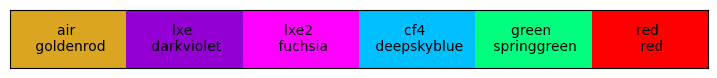

In [1]:
from GenPaths import * # this provides PROPATH which helps load stuff (and the paths to find the PDEhelpers stuff)

import pandas as pd
import matplotlib.pyplot as plt

from scipy import optimize as opt
import iminuit
from iminuit import Minuit

from PDEhelpers.OpticsDataLoader import *
import PDEhelpers.MathEquations as ME
from PDEhelpers.PhotonInfo import * # this calls DataLoader when defining init
# from PDEhelpers.PNJunction import *
import PDEhelpers.PNJunction as PNJ

import PDE_fittingTools as SS

import PDEhelpers.PDEStyle as MS
MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like

rad2deg = 180/np.pi

# MS.ShowMyStyles() # for colors
# ms = MS.MyStyleSet() # object to use like
# ms.SetMPLcolors() # turn off with "off" option

In [2]:
def get_csv_files_with_identifier(directory, str_id):
    csv_files = []
    for file in os.listdir(directory):
        if file.endswith(".csv") and str_id in file:
            csv_files.append(os.path.join(directory, file))
    return csv_files

def get_chars_before(toSearch, findBefore, numBefore = 3):
    index1 = toSearch.find(findBefore)
    if index1 == -1:
        return None
    else:
        return toSearch[index1-numBefore:index1]

class AngularData:
    
    def __init__(self, path, comment="#"):
        self.df = pd.read_csv(path, header = 0, comment=comment)
        self.names = self.df.columns.values
        self.baseName = os.path.basename(path)
        
        self.wlen = get_chars_before(self.baseName, "nm_", numBefore=3)
        self.voltage = get_chars_before(self.baseName, "oV", numBefore=1)
      
        self.Ipeak = None
        self.IpeakErr = None
        return None
    
    def RemoveMax(self):
        maxAngle = self.df[self.names[0]].max()
        # remove all rows with max angle
        self.df = self.df[self.df[self.names[0]] != maxAngle]
        return None
    
    def LoadData(self):
        self.RemoveMax()
        dataNames = self.df.columns.values
        # print(dataNames)
        
        self.xRaw = -1*self.df[dataNames[0]].values
        self.Iraw = self.df[dataNames[1]].values
        self.IrawErr = self.df[dataNames[2]].values
        
        # print(self.Iraw)
        # print(self.xRaw)
        
        self.Ipeak = self.df[   self.df[dataNames[0]] == 0].values[0][1]
        self.IpeakErr = self.df[self.df[dataNames[0]] == 0].values[0][2]
        
        self.Inorm = self.Iraw/self.Ipeak
        self.InormErr = self.Inorm * np.sqrt((self.IrawErr/self.Iraw)**2 + (self.IpeakErr/self.Ipeak)**2)
        return None
    
    
    def Describe(self, verbose = False):
        print("---- Angular Data ----")
        print("Base Name:", self.baseName) if verbose else None
        print("Voltage:", self.voltage) if verbose else None
        print("Wavelength:", self.wlen)
        print(f"peak Current: {self.Ipeak*1e6:0.3f} +/- {self.IpeakErr*1e6:0.4f}") if self.Ipeak is not None else None
        print("----- \n")
        return None

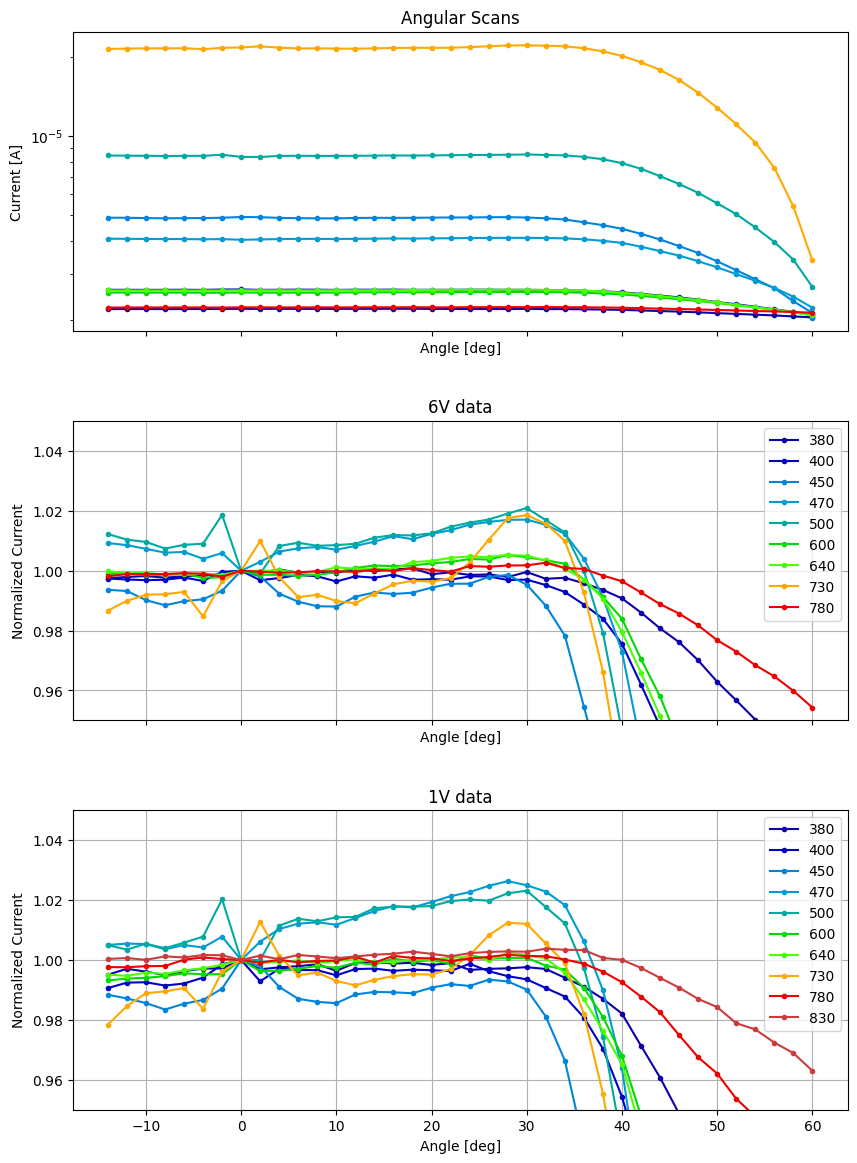

In [19]:
dataPath = os.path.join(PROPATH, "..", "veraData/HPK_angularScans_March2024")

filelist_6V = get_csv_files_with_identifier(dataPath, "6oV")
sorted_f6V_list = sorted(filelist_6V, key=lambda file: get_chars_before(file, "nm_", numBefore=3))

filelist_1V = get_csv_files_with_identifier(dataPath, "1oV")
sorted_f1V_list = sorted(filelist_1V, key=lambda file: get_chars_before(file, "nm_", numBefore=3))

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, sharex=True, figsize = (10, 14))

for i, file in enumerate(sorted_f6V_list):
    if "830" in file:
        continue
    angData = AngularData(file)
    angData.LoadData()
    # angData.Describe()
    
    ax1.semilogy(angData.xRaw, angData.Iraw, marker = ".", color= MS.map_value_to_hsv(angData.wlen, 300, 850, map="nipy_spectral"), label = angData.wlen)
    ax2.plot(angData.xRaw, angData.Inorm, marker = ".", color = MS.map_value_to_hsv(angData.wlen, 300, 850, map="nipy_spectral"), label = angData.wlen)

for i, file in enumerate(sorted_f1V_list):
    angData = AngularData(file)
    angData.LoadData()
    # angData.Describe()
    
    ax3.plot(angData.xRaw, angData.Inorm, marker = ".", color = MS.map_value_to_hsv(angData.wlen, 300, 850, map="nipy_spectral"), label = angData.wlen)

ax1.set_title("Angular Scans")
ax1.set_ylabel("Current [A]")
ax1.set_xlabel("Angle [deg]")

ax2.set_xlabel("Angle [deg]")
ax2.set_title("6V data")
ax2.set_ylabel("Normalized Current")
ax2.set_ylim(0.95, 1.05)
ax2.legend()
ax2.grid()

ax3.set_xlabel("Angle [deg]")
ax3.set_title("1V data")
ax3.set_ylabel("Normalized Current")
ax3.set_ylim(0.95, 1.05)
ax3.legend()
ax3.grid()

plt.subplots_adjust(hspace=0.3)
plt.show()

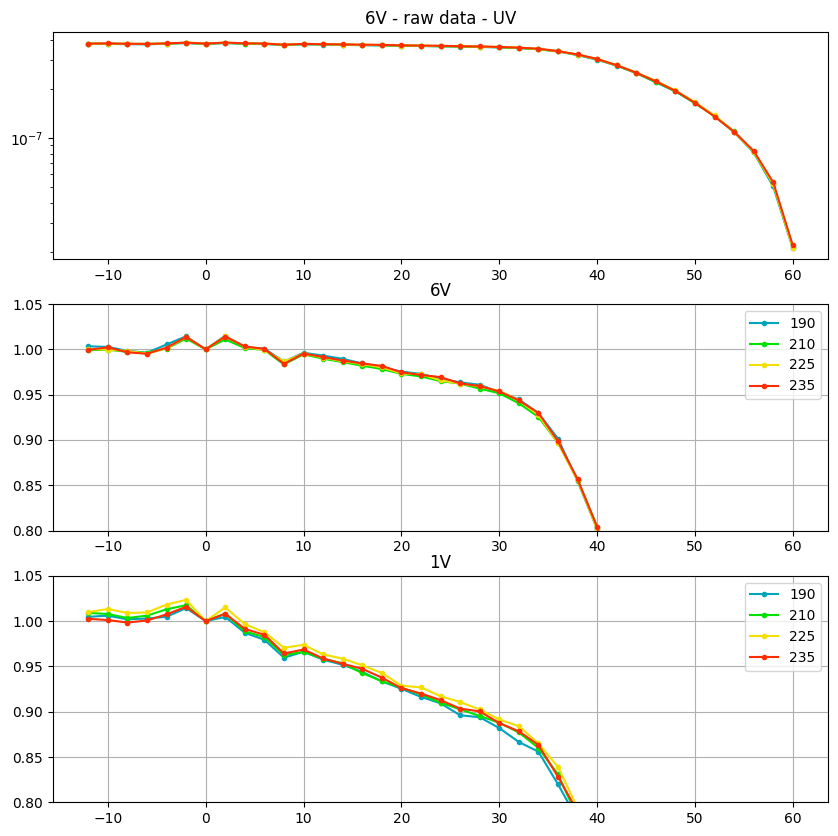

In [4]:
dataPath = os.path.join(PROPATH, "..", "veraData/angular_scans_VUV_feb2024")

filelist_6V = get_csv_files_with_identifier(dataPath, "6oV")
sorted_f6V_list = sorted(filelist_6V, key=lambda file: get_chars_before(file, "nm_", numBefore=3))

filelist_1V = get_csv_files_with_identifier(dataPath, "1oV")
sorted_f1V_list = sorted(filelist_1V, key=lambda file: get_chars_before(file, "nm_", numBefore=3))

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize = (10, 10))

for i, file in enumerate(sorted_f6V_list):
    angData = AngularData(file)
    angData.LoadData()
    # angData.Describe()
    
    ax1.semilogy(angData.xRaw, angData.Iraw, marker = ".", color= MS.map_value_to_hsv(angData.wlen, 160, 250, map="nipy_spectral"), label = angData.wlen)
    ax2.plot(angData.xRaw, angData.Inorm, marker = ".", color = MS.map_value_to_hsv(angData.wlen, 160, 250, map="nipy_spectral"), label = angData.wlen)

ax1.set_title("6V - raw data - UV")
ax2.set_title("6V")

for i, file in enumerate(sorted_f1V_list):
    angData = AngularData(file)
    angData.LoadData()
    # angData.Describe()
    
    ax3.plot(angData.xRaw, angData.Inorm, marker = ".", color = MS.map_value_to_hsv(angData.wlen, 160, 250, map="nipy_spectral"), label = angData.wlen)
ax3.set_title("1V")

ax2.set_ylim(0.8, 1.05)


ax3.set_ylim(0.8, 1.05)
ax3.legend()

ax2.grid()
ax2.legend()
ax3.grid()
plt.show()

In [5]:
fpath = os.path.join(PROPATH, "../veraData/HPK_angularScans_March2024")

# flist = ["HPKW_angular_190nm_-110C_0.5mm_slit_6oV.csv", "HPKW_angular_210nm_-110C_0.5mm_slit_6oV.csv", "HPKW_angular_220nm_-110C_0.5mm_slit_6oV.csv", "HPKW_angular_235nm_-110C_0.5mm_slit_6oV.csv"]

# dx_190_6V, dy_190_6V, dyErr_190_6V = np.genfromtxt(fpath+"/HPKW_angular_190nm_-110C_0.5mm_slit_1oV.csv", delimiter=",", skip_header=1)
df_190_6v = pd.read_csv(fpath+"/HPKW_angular_500nm_23C_0.5mm_slit_6oV.csv", header=0)
print(df_190_6v.head())
print(df_190_6v.tail())

names=df_190_6v.columns
print("columns:", names)
print("unique angles:", df_190_6v[names[0]].unique())

# drop data for maximum angles (where diode is turned off)
print("max angle:", df_190_6v[names[0]].values.max())
df_190_6v = df_190_6v[df_190_6v[names[0]] < df_190_6v[names[0]].values.max()]

# get values at normal incidence
normalCurrent = df_190_6v.loc[df_190_6v[names[0]] == 0, names[1]].values[0]
normalError = df_190_6v.loc[df_190_6v[names[0]] == 0, names[2]].values[0]
print(normalCurrent)

print(names)
dx_190_6V = df_190_6v[names[0]].values
dx_190_6V *= -1 # flip sign

dy_190_6Vraw = df_190_6v[names[1]].values
dy_190_6V_norm = dy_190_6Vraw/normalCurrent # normalize to max value

dyErr_190_6V = df_190_6v[names[2]].values
dyErr_190_6V = dy_190_6V_norm * np.sqrt((dyErr_190_6V/dy_190_6Vraw)**2 + (normalError/normalCurrent)**2)

   Angle (starting from -60deg)   Current         Error
0                            16  0.000002  2.980380e-09
1                           -60  0.000003  4.317750e-09
2                           -58  0.000003  6.296150e-09
3                           -56  0.000004  7.285810e-09
4                           -54  0.000004  7.369390e-09
    Angle (starting from -60deg)   Current         Error
36                            10  0.000008  1.134750e-08
37                            12  0.000008  1.248610e-08
38                            14  0.000008  1.051240e-08
39                            16  0.000008  1.226590e-08
40                            16  0.000002  3.494760e-09
columns: Index(['Angle (starting from -60deg)', 'Current', 'Error'], dtype='object')
unique angles: [ 16 -60 -58 -56 -54 -52 -50 -48 -46 -44 -42 -40 -38 -36 -34 -32 -30 -28
 -26 -24 -22 -20 -18 -16 -14 -12 -10  -8  -6  -4  -2   0   2   4   6   8
  10  12  14]
max angle: 16
8.33791e-06
Index(['Angle (starting from -60deg)

(0.7, 1.05)

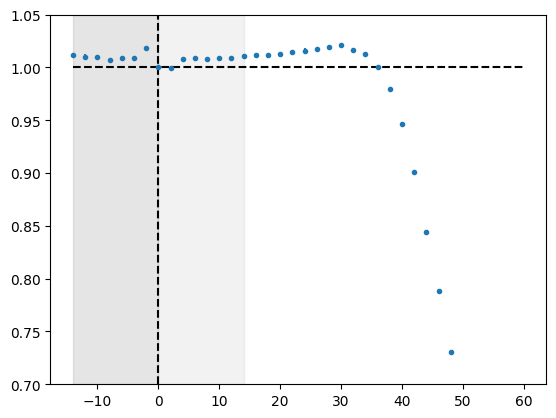

In [6]:
plt.errorbar(dx_190_6V, dy_190_6V_norm, yerr=dyErr_190_6V, fmt='.', label="190nm 6V")
plt.hlines(1, min(dx_190_6V), max(dx_190_6V), color='k', linestyle='--')
plt.vlines(0, 0.7, 1.05, color='k', linestyle='--')
plt.fill_between([0, min(dx_190_6V)], 0.7, 1.05, color='gray', alpha=0.2)
plt.fill_between([-min(dx_190_6V), 0], 0.7, 1.05, color='gray', alpha=0.1)

# plt.xlim(-15, 50)
plt.ylim(0.7, 1.05)
# plt.yscale('log')

In [7]:
# ## Rotating data points
# import numpy as np

# def rotate_points(x, y, x_center, y_center, angle):
#     # Convert the angle to radians
#     angle_rad = np.radians(angle)

#     # Create the rotation matrix
#     rotation_matrix = np.array([
#         [np.cos(angle_rad), -np.sin(angle_rad)],
#         [np.sin(angle_rad),  np.cos(angle_rad)]
#     ])

#     # Subtract the rotation center from the points
#     x -= x_center
#     y -= y_center

#     # Rotate the points
#     x_new, y_new = np.dot(rotation_matrix, [x, y])

#     # Add the rotation center back to the points
#     x_new += x_center
#     y_new += y_center

#     return x_new, y_new

In [8]:
# print("min X: ", min(dx_190_6V))

# xSymmetric = dx_190_6V[dx_190_6V <= -min(dx_190_6V)]
# ySymmetric = dy_190_6V_norm[dx_190_6V <= -min(dx_190_6V)]
# ySymmErrors = dyErr_190_6V[dx_190_6V <= -min(dx_190_6V)]

# plt.errorbar(xSymmetric, ySymmetric, yerr=ySymmErrors, fmt='r.', label="Symmetric 190nm 6V")

-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMerged/silicon_crystalline_lithoAndSchinke_merged.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/PDEhelpers/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------


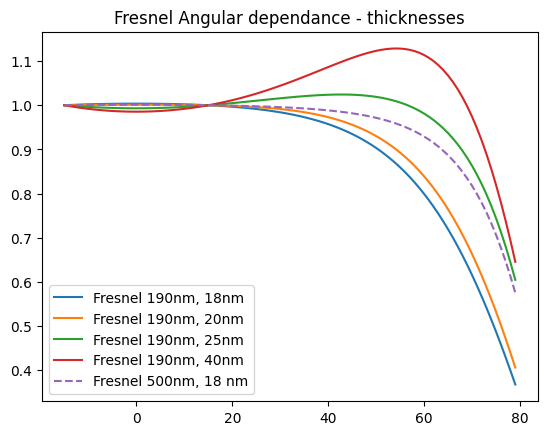

In [9]:
xAng = np.arange(-15, 80, 1)
photon_190 = PhotonInfo(wlen=190, theta_1=xAng)

thicknesses = [18, 20, 25, 40]
for t in thicknesses:
    ys = photon_190.T_total_windowAndOxide(t)
    plt.plot(xAng, ys/ys[0], label="Fresnel 190nm, "+str(t)+"nm")
    
photon_500 = PhotonInfo(wlen=500, theta_1=xAng).T_total_windowAndOxide(18)
plt.plot(xAng, photon_500/photon_500[0], linestyle = "--", label="Fresnel 500nm, 18 nm")

plt.title("Fresnel Angular dependance - thicknesses")
plt.legend()
plt.show()

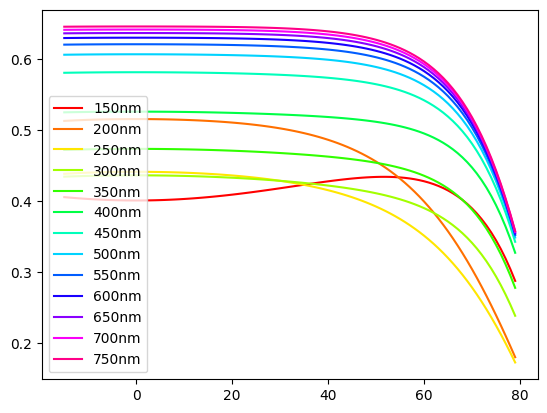

In [10]:
xAng = np.arange(-15, 80, 1)
tGood = 18

loopWlens = np.arange(150, 800, 50)
cmap = plt.get_cmap('hsv')
colors = [cmap(i) for i in np.linspace(0, 1, len(loopWlens)+1)]

for i, wl in enumerate(loopWlens):
    photon = PhotonInfo(wlen=wl, theta_1=xAng)
    tlabel=None if i % 2 == 0 else "Fresnel "+str(wl)+"nm"
    tlabel =str(wl)+"nm"
    plt.plot(xAng, photon.T_total_windowAndOxide(thick_oxide=tGood), color = colors[i], label=tlabel)
    
    
plt.legend()
plt.show()

NameError: name 'FF_theta_absolute' is not defined

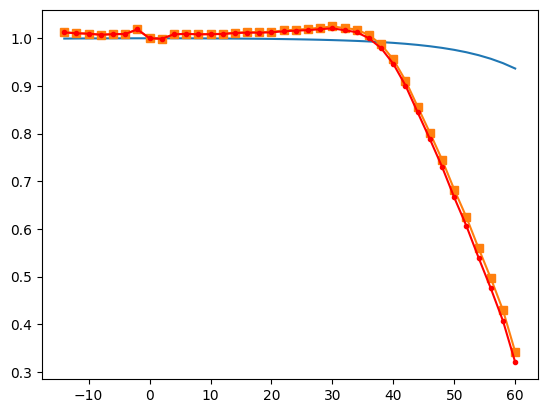

In [11]:
## plot together

photon_190 = PhotonInfo(wlen=500, theta_1=dx_190_6V)
zeroIndice = np.where(dx_190_6V == 0)[0][0]
ttGood=14

yFresnel_190 = photon_190.T_total_windowAndOxide(ttGood)
yFresnel_190_norm = yFresnel_190/yFresnel_190[zeroIndice]

# data
plt.errorbar(dx_190_6V, dy_190_6V_norm, yerr=dyErr_190_6V, marker=".", color="red", label="data, 190nm 6V")

# fresnel transmission
plt.plot(dx_190_6V, yFresnel_190_norm, label="190nm Fresnel normalized")

# data/fresnel (epirical FF)
fillFactorEmpirical = dy_190_6V_norm/yFresnel_190_norm
plt.plot(dx_190_6V, fillFactorEmpirical, marker = "s", label="190nm, Empirical FF")

height = 0.7
plt.plot(dx_190_6V, FF_theta_absolute(p, ffc, height, dx_190_6V)/FF, label="analytic FF, h={} um".format(height))



plt.legend()
plt.ylim(0.7, 1.05)
plt.xlim(-15, 40)
plt.grid()

plt.show()

In [ ]:
flist = ["HPKW_angular_190nm_-110C_0.5mm_slit_6oV.csv", "HPKW_angular_210nm_-110C_0.5mm_slit_6oV.csv", "HPKW_angular_220nm_-110C_0.5mm_slit_6oV.csv", "HPKW_angular_235nm_-110C_0.5mm_slit_6oV.csv"]

